# 08 · Check clean metadata uncertainty, calibration and decisions

Reproduce the original robustness analysis using saved training-only maps and cutoffs, paired patient intervals, reliability diagrams, class support and review workload. Defer the final full-development fit.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [08_metadata_robustness.ipynb](../Subset/08_metadata_robustness.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '08_metadata_robustness'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Match scores and audit the training-only procedure

For each outer pool, four preserved training folds supply inner OOF spline scores. Those scores alone fit the sigmoid recalibrator and select the highest cutoff meeting the academic 80% training recall target. A fresh outer-training spline then scores untouched outer patients. Outer recall can differ from 80%; this is a research scenario, not a clinical target.

In [2]:
import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))

calibration = meta["calibration"]
audit = pd.read_csv(meta["base"] / "spline_inner_audit.csv")
assert audit.patient_overlap.eq(0).all()
display(audit.round(5))
display(calibration.groupby("fold").agg(raw_cutoff=("raw_threshold", "first"), recalibrated_cutoff=("calibrated_threshold", "first"), images=("target", "size"), malignant_images=("target", "sum")))

,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


,outer_fold,inner_heldout_fold,fit_patients,validation_patients,patient_overlap,fit_positive_images,validation_positive_images,outer_validation_patients,calibrator_slope,calibrator_intercept
0,0,1,254,84,0,77,26,84,0.59790,-1.57685
1,0,2,251,87,0,77,26,84,0.59790,-1.57685
2,0,3,256,82,0,78,25,84,0.59790,-1.57685
3,0,4,253,85,0,77,26,84,0.59790,-1.57685
4,1,0,254,84,0,77,24,84,0.78167,-0.84353
5,1,2,251,87,0,75,26,84,0.78167,-0.84353
6,1,3,256,82,0,76,25,84,0.78167,-0.84353
7,1,4,253,85,0,75,26,84,0.78167,-0.84353
8,2,0,251,84,0,77,24,87,0.75010,-0.98382
9,2,1,251,84,0,75,26,87,0.75010,-0.98382


,raw_cutoff,recalibrated_cutoff,images,malignant_images
fold,,,,
0,0.010618,0.013546,1344,24
1,0.011326,0.012907,1366,26
2,0.009737,0.011535,1328,26
3,0.010137,0.011808,1371,25
4,0.011971,0.013660,1297,26


## 2. Read paired whole-patient ranking intervals

The saved comparison uses 2,000 seed-42 draws within outer folds, repeating every image of a sampled patient together. NN and spline receive identical multiplicities. Mean-fold AP is primary; pooled differences are secondary. Intervals hold fitted predictions fixed and omit retraining, architecture search and distribution shift.

,model,aggregation,metric,estimate,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed,interval
0,metadata_nn_mean,mean_fold,average_precision,0.05957,0.04404,0.10590,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
8,spline_raw,mean_fold,average_precision,0.06484,0.04557,0.11504,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."


,comparison,aggregation,metric,difference,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed,role
16,metadata_nn_mean minus spline_raw,mean_fold,average_precision,-0.00527,-0.02552,0.00760,2000,2000,0,42,predeclared development comparison
17,metadata_nn_mean minus spline_raw,mean_fold,roc_auc,0.02106,-0.00563,0.04133,2000,2000,0,42,predeclared development comparison


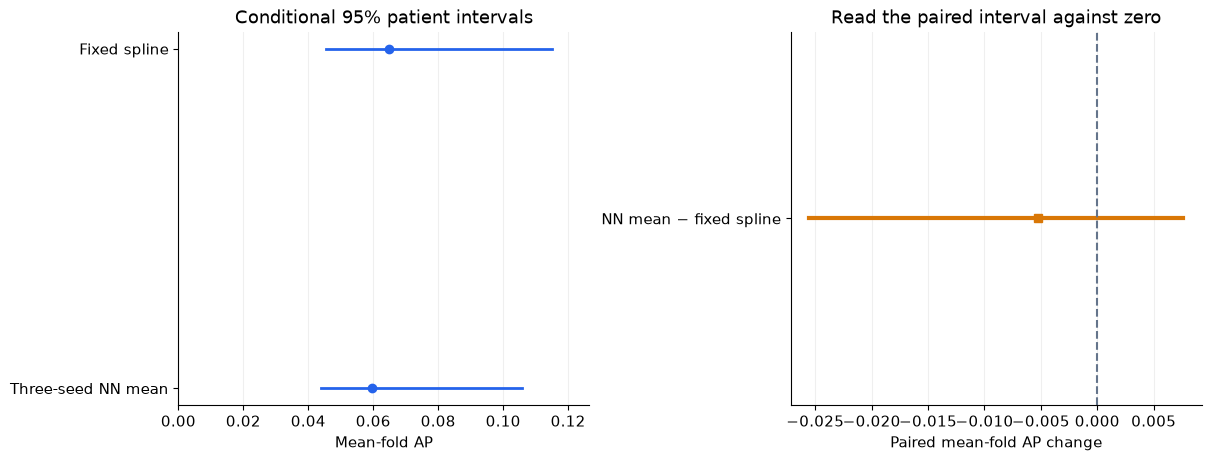

In [3]:
evaluation = latest_evaluation(ROOT)
if "output_directory" in evaluation:
    folder = ROOT / evaluation["output_directory"]
    absolute = pd.read_csv(folder / "bootstrap_intervals.csv")
    paired = pd.read_csv(folder / "paired_comparisons.csv")
    left = absolute.loc[absolute.model.isin(["spline_raw", "metadata_nn_mean"]) & absolute.aggregation.eq("mean_fold") & absolute.metric.eq("average_precision")]
    right = paired.loc[paired.comparison.eq("metadata_nn_mean minus spline_raw") & paired.aggregation.eq("mean_fold") & paired.metric.isin(["average_precision", "roc_auc"])]
    display(left.round(5)); display(right.round(5))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    for index, row in enumerate(left.itertuples()):
        axes[0].plot([row.ci_lower, row.ci_upper], [index, index], color="#2563eb", linewidth=2)
        axes[0].plot(row.estimate, index, "o", color="#2563eb")
    axes[0].set(yticks=range(len(left)), yticklabels=[LABELS[name] for name in left.model], xlabel="Mean-fold AP", title="Conditional 95% patient intervals", xlim=(0, max(.12, float(left.ci_upper.max()) * 1.1)))
    ap = right.loc[right.metric.eq("average_precision")]
    for row in ap.itertuples():
        axes[1].plot([row.ci_lower, row.ci_upper], [0, 0], color="#d97706", linewidth=3)
        axes[1].plot(row.difference, 0, "s", color="#d97706")
    axes[1].axvline(0, linestyle="--", color="#64748b")
    axes[1].set(yticks=[0], yticklabels=["NN mean − fixed spline"], xlabel="Paired mean-fold AP change", title="Read the paired interval against zero")
    for ax in axes: ax.grid(axis="x", alpha=.2)
    finish_figure(fig, "metadata_paired_patient_intervals")
else:
    display(Markdown("**Pending:** verified clean paired intervals have not been generated."))

## 3. Compare probability error and equal-patient weighting

Raw versus recalibrated score error must be assessed on outer patients. Equal-patient image weights 1/(retained images for that patient) provide a secondary diagnostic for unequal patient contribution; they do not convert the task into patient cancer diagnosis or change the primary metric.

In [4]:
probabilities = {"spline_raw": calibration.p_spline_raw.to_numpy(), "spline_calibrated": calibration.p_spline_calibrated.to_numpy(), "metadata_nn_mean": scores["metadata_nn_mean"]}
display(metric_table(frame, probabilities, list(probabilities)).query("scope != 'fold'").round(5))
from sklearn.metrics import average_precision_score, roc_auc_score
weights = 1 / frame.groupby("patient_id").patient_id.transform("size").to_numpy()
display(pd.DataFrame([{"model": LABELS[name], "pooled_image_AP": average_precision_score(frame.target, values), "equal_patient_AP": average_precision_score(frame.target, values, sample_weight=weights), "pooled_image_AUC": roc_auc_score(frame.target, values), "equal_patient_AUC": roc_auc_score(frame.target, values, sample_weight=weights)} for name, values in probabilities.items()]).round(5))

,model,scope,fold,average_precision,roc_auc,log_loss,brier
5,spline_raw,mean_fold,NaN,0.06484,0.65563,0.09101,0.01842
6,spline_raw,pooled,NaN,0.04921,0.64283,0.09095,0.01841
12,spline_calibrated,mean_fold,NaN,0.06484,0.65563,0.09083,0.01841
13,spline_calibrated,pooled,NaN,0.04781,0.63810,0.09078,0.01840
19,metadata_nn_mean,mean_fold,NaN,0.05957,0.67669,0.09017,0.01838
20,metadata_nn_mean,pooled,NaN,0.04768,0.66946,0.09011,0.01837


,model,pooled_image_AP,equal_patient_AP,pooled_image_AUC,equal_patient_AUC
0,Fixed spline,0.04921,0.10143,0.64283,0.69201
1,Training-only recalibrated spline,0.04781,0.10203,0.63810,0.68965
2,Three-seed NN mean,0.04768,0.08996,0.66946,0.71335


## 4. Read reliability diagrams and score distributions

Five approximate equal-count bins keep equal scores together. The horizontal axis is mean estimated risk and the vertical axis is observed malignant-image fraction; the diagonal marks agreement. Vertical intervals use 2,000 whole-patient draws within folds with fixed bins. A patient can appear in several bins, and sparse malignant support makes the curve noisy. Histogram movements do not prove better calibration.

,model,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,observed_lower,observed_upper,valid_draws
0,spline_raw,1,1371,15,0.00759,0.01094,0.00281,0.00915,121,0.00415,0.01953,2000
1,spline_raw,2,1329,16,0.01069,0.01204,0.00918,0.01186,162,0.00574,0.01977,2000
2,spline_raw,3,1334,22,0.01377,0.01649,0.01194,0.01604,187,0.00883,0.02613,2000
3,spline_raw,4,1344,18,0.01976,0.01339,0.01618,0.02507,203,0.00676,0.02139,2000
4,spline_raw,5,1328,56,0.04893,0.04217,0.02538,0.42128,198,0.02789,0.05992,2000
5,spline_calibrated,1,1353,19,0.00966,0.01404,0.00435,0.01121,127,0.00608,0.02333,2000
6,spline_calibrated,2,1334,12,0.01264,0.00900,0.01121,0.01403,168,0.00384,0.01558,2000
7,spline_calibrated,3,1337,22,0.01522,0.01645,0.01403,0.01690,173,0.00823,0.02739,2000
8,spline_calibrated,4,1345,18,0.01968,0.01338,0.01705,0.02344,204,0.00680,0.02138,2000
9,spline_calibrated,5,1337,56,0.03708,0.04188,0.02371,0.25130,199,0.02766,0.05943,2000


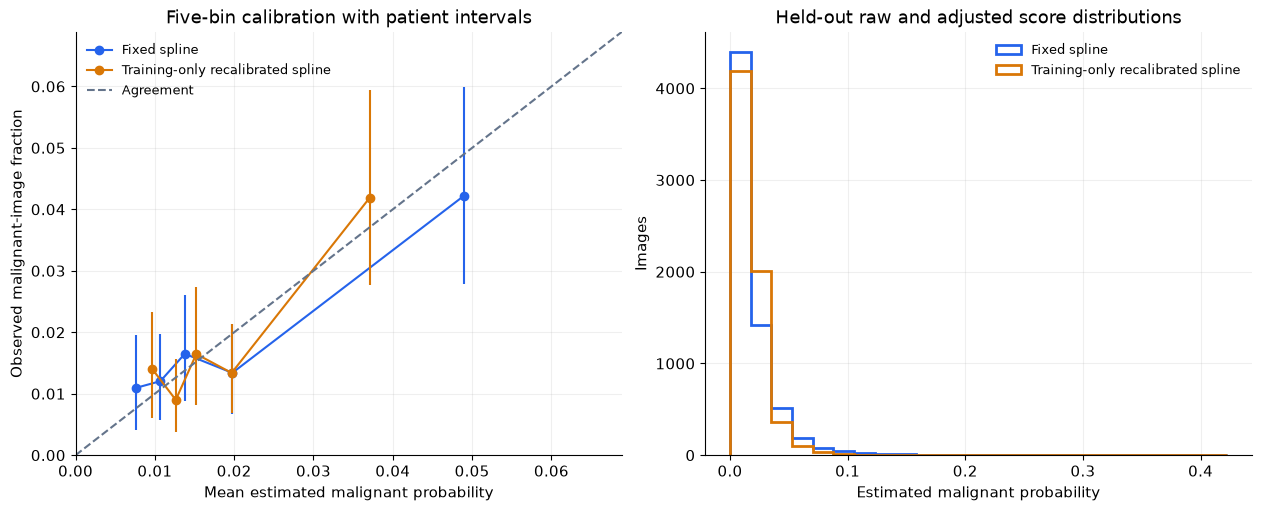

In [5]:
reliability = reliability_table(frame, {name: values for name, values in probabilities.items() if name != "metadata_nn_mean"})
display(reliability.round(5))
save_metadata_table(ROOT, "08_metadata_robustness", "reliability_bins_with_patient_intervals", reliability)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), layout="constrained")
maximum = max(float(values.max()) for name, values in probabilities.items() if name != "metadata_nn_mean")
for index, name in enumerate(["spline_raw", "spline_calibrated"]):
    rows = reliability.loc[reliability.model.eq(name)]
    axes[0].plot(rows.mean_probability, rows.observed_rate, "o-", color=COLORS[index], label=LABELS[name])
    axes[0].vlines(rows.mean_probability, rows.observed_lower, rows.observed_upper, color=COLORS[index])
    axes[1].hist(probabilities[name], bins=np.linspace(0, maximum + .001, 25), histtype="step", linewidth=2, color=COLORS[index], label=LABELS[name])
limit = max(float(reliability.mean_probability.max()), float(reliability.observed_upper.max())) * 1.15
axes[0].plot([0, limit], [0, limit], "--", color="#64748b", label="Agreement")
axes[0].set(xlabel="Mean estimated malignant probability", ylabel="Observed malignant-image fraction", title="Five-bin calibration with patient intervals", xlim=(0, limit), ylim=(0, limit))
axes[1].set(xlabel="Estimated malignant probability", ylabel="Images", title="Held-out raw and adjusted score distributions")
for ax in axes: ax.legend(frameon=False, fontsize=9); ax.grid(alpha=.2)
finish_figure(fig, "metadata_reliability_and_score_distributions")

## 5. Assess frozen cutoffs on outer patients

Each outer fold uses its own training-selected cutoff. Combine its saved decisions without choosing another cutoff from outer labels. Sensitivity counts malignant images found; specificity counts benign images left unflagged; precision is malignant share among flags; flagged fraction estimates review workload. These are image-level decisions with patient-cluster uncertainty.

,procedure,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,Fixed spline,102,4495,2084,25,0.80315,0.31677,0.02219,0.68551
1,Training-only recalibrated spline,102,4495,2084,25,0.80315,0.31677,0.02219,0.68551


,procedure,metric,estimate,ci_lower,ci_upper,valid_draws,requested_draws
0,Fixed spline,sensitivity,0.80315,0.71629,0.88889,2000,2000
1,Fixed spline,specificity,0.31677,0.26478,0.36956,2000,2000
2,Fixed spline,precision,0.02219,0.01675,0.02852,2000,2000
3,Fixed spline,flagged_fraction,0.68551,0.63269,0.73724,2000,2000
4,Training-only recalibrated spline,sensitivity,0.80315,0.71629,0.88889,2000,2000
5,Training-only recalibrated spline,specificity,0.31677,0.26478,0.36956,2000,2000
6,Training-only recalibrated spline,precision,0.02219,0.01675,0.02852,2000,2000
7,Training-only recalibrated spline,flagged_fraction,0.68551,0.63269,0.73724,2000,2000


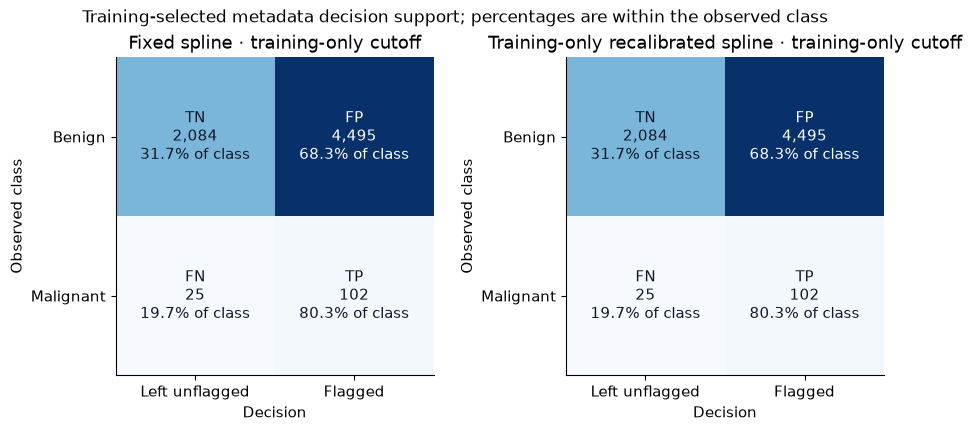

In [6]:
decision_rows, interval_rows = [], []
for scale, name in [("raw", "spline_raw"), ("calibrated", "spline_calibrated")]:
    decisions = calibration[f"decision_{scale}"].to_numpy()
    decision_rows.append({"procedure": LABELS[name], **decision_metrics(frame.target, decisions)})
    ci = decision_intervals(frame, decisions)
    ci.insert(0, "procedure", LABELS[name]); interval_rows.append(ci)
decision_summary = pd.DataFrame(decision_rows)
decision_ci = pd.concat(interval_rows, ignore_index=True)
display(decision_summary.round(5)); display(decision_ci.round(5))
save_metadata_table(ROOT, "08_metadata_robustness", "training_only_decision_summary", decision_summary)
save_metadata_table(ROOT, "08_metadata_robustness", "training_only_decision_intervals", decision_ci)
scenarios = [(LABELS[name] + " · training-only cutoff", calibration[column].to_numpy()) for name, column in [("spline_raw", "decision_raw"), ("spline_calibrated", "decision_calibrated")]]
finish_figure(confusion_figure(frame.target, scenarios, "Training-selected metadata decision support"), "metadata_training_only_confusions")

## 6. Read detection and review-workload intervals

The same 2,000 patient draws assess raw and recalibrated frozen decisions. Intervals do not reselect cutoffs in each draw or guarantee a clinical workload. Undefined rates retain missing values, and valid-draw counts show whether scarce classes limit estimation.

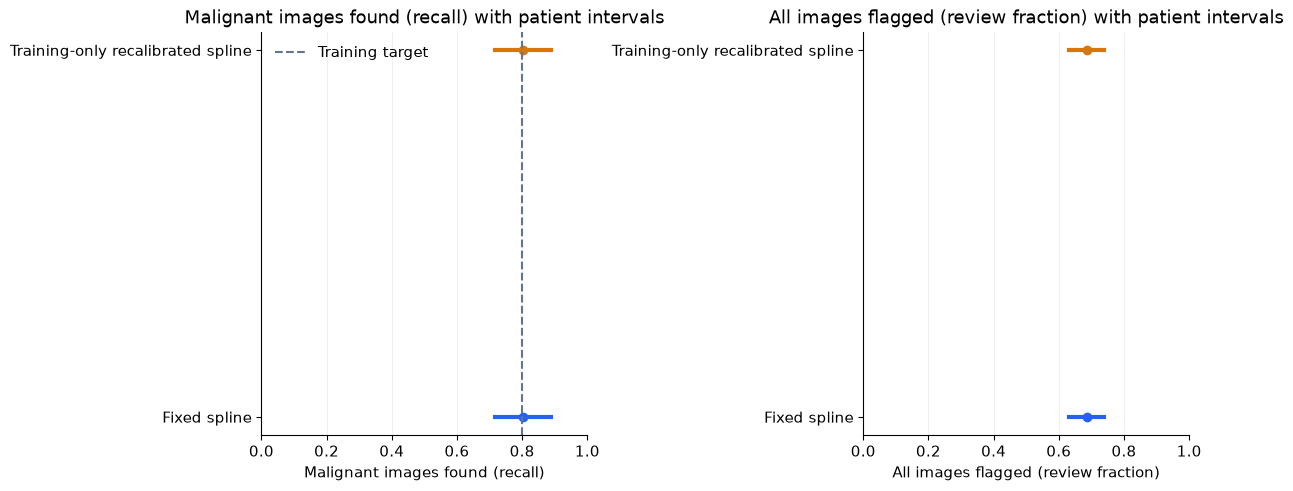

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, metric, label in zip(axes, ["sensitivity", "flagged_fraction"], ["Malignant images found (recall)", "All images flagged (review fraction)"]):
    rows = decision_ci.loc[decision_ci.metric.eq(metric)].reset_index(drop=True)
    for index, row in rows.iterrows():
        ax.plot([row.ci_lower, row.ci_upper], [index, index], color=COLORS[index], linewidth=3)
        ax.plot(row.estimate, index, "o", color=COLORS[index])
    ax.set(yticks=range(len(rows)), yticklabels=rows.procedure, xlabel=label, title=label + " with patient intervals", xlim=(0, 1))
    ax.grid(axis="x", alpha=.2)
axes[0].axvline(.8, color="#64748b", linestyle="--", label="Training target")
axes[0].legend(frameon=False)
finish_figure(fig, "metadata_detection_and_review_intervals")

## 7. Check age, sex, site and site availability with support

Use raw spline scores and the same frozen decision procedure for every subgroup; no subgroup-specific cutoff is fitted. AP depends partly on malignant prevalence. One patient's images may occupy multiple age/site groups, so counts cannot be summed as independent patients. Secondary intervals use 2,000 seed-42 whole-patient draws within outer folds. Fewer than ten malignant patients triggers interval suppression as a reporting caution, not a zero metric; undefined values remain missing.

,field,group,images,patients,malignant_images,malignant_patients,prevalence,average_precision,roc_auc,sensitivity,precision,flagged_fraction,valid_draws,evidence_note
0,Age band,<50,2981,189,32,23,0.01073,0.01262,0.48331,0.43750,0.01256,0.37404,2000,Exploratory; shared frozen cutoff; no subgroup...
1,Age band,>=50,3725,269,95,65,0.02550,0.06599,0.63982,0.92632,0.02527,0.93477,2000,Exploratory; shared frozen cutoff; no subgroup...
2,Sex,female,3477,204,53,37,0.01524,0.03378,0.62111,0.71698,0.01913,0.57118,2000,Exploratory; shared frozen cutoff; no subgroup...
3,Sex,male,3229,218,74,51,0.02292,0.06256,0.64997,0.86486,0.02451,0.80861,2000,Exploratory; shared frozen cutoff; no subgroup...
4,Site,Unknown,195,53,2,2,0.01026,0.07772,0.58290,1.00000,0.01235,0.83077,0,Sparse: fewer than 10 malignant patients; inte...
5,Site,head/neck,393,179,21,21,0.05344,0.14327,0.67531,1.00000,0.05344,1.00000,2000,Exploratory; shared frozen cutoff; no subgroup...
6,Site,lower extremity,1620,327,25,23,0.01543,0.04594,0.59136,0.72000,0.01739,0.63889,2000,Exploratory; shared frozen cutoff; no subgroup...
7,Site,oral/genital,33,20,3,2,0.09091,0.08425,0.17222,1.00000,0.09091,1.00000,0,Sparse: fewer than 10 malignant patients; inte...
8,Site,palms/soles,70,40,0,0,0.00000,NaN,NaN,NaN,0.00000,0.58571,0,Sparse: fewer than 10 malignant patients; inte...
9,Site,torso,3351,398,54,41,0.01611,0.03852,0.62922,0.70370,0.01890,0.60012,2000,Exploratory; shared frozen cutoff; no subgroup...


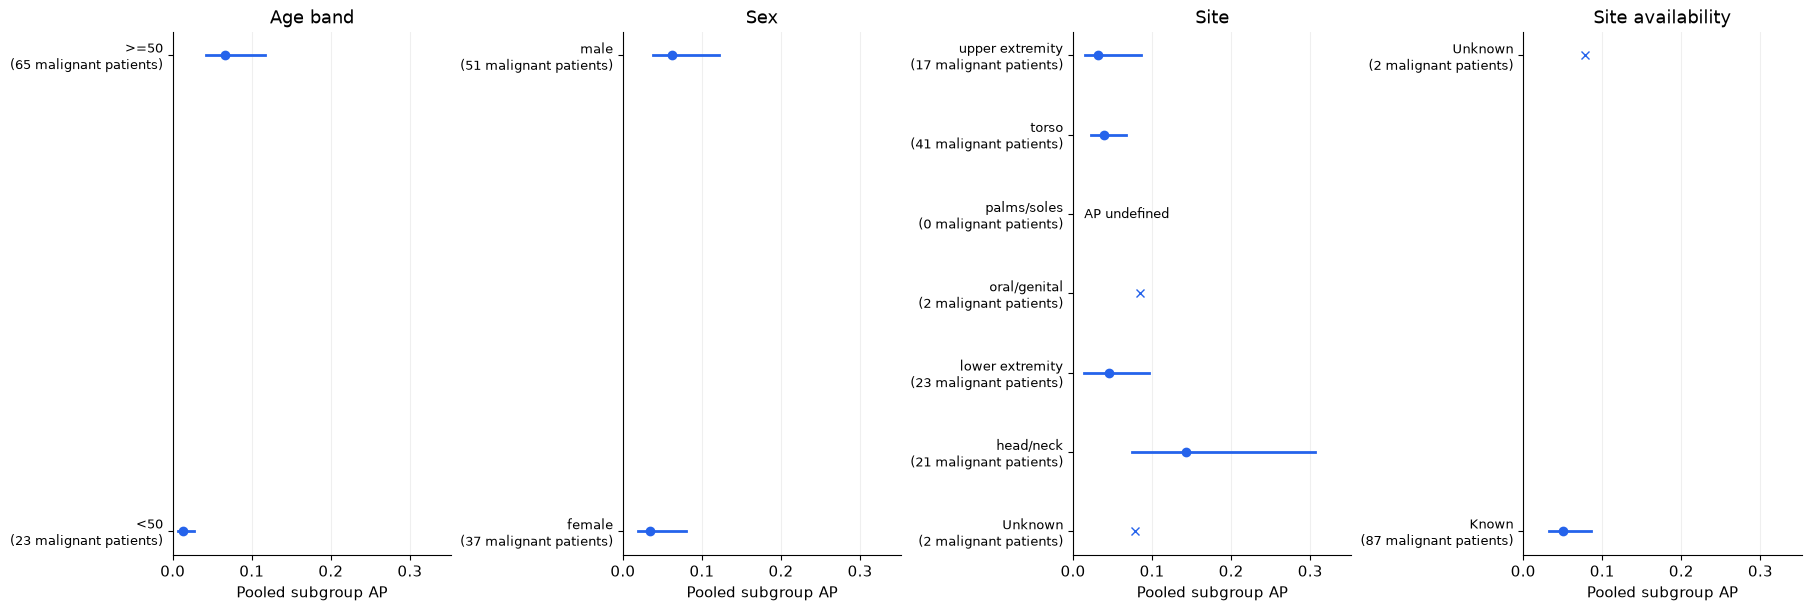

In [8]:
diagnostic_frame = bundle["frame"].set_index("image_name").loc[frame.image_id].reset_index()
subgroups = subgroup_diagnostics(diagnostic_frame, calibration.p_spline_raw.to_numpy(), calibration.decision_raw.to_numpy())
save_metadata_table(ROOT, "08_metadata_robustness", "subgroup_diagnostics_with_patient_support", subgroups)
display(subgroups[["field", "group", "images", "patients", "malignant_images", "malignant_patients", "prevalence", "average_precision", "roc_auc", "sensitivity", "precision", "flagged_fraction", "valid_draws", "evidence_note"]].round(5))
fig, axes = plt.subplots(1, 4, figsize=(18, 6), layout="constrained")
limit = max(float(subgroups.average_precision.max()), float(subgroups.average_precision_upper.max())) * 1.15
for ax, field in zip(axes, ["Age band", "Sex", "Site", "Site availability"]):
    rows = subgroups.loc[subgroups.field.eq(field)].reset_index(drop=True)
    for index, row in rows.iterrows():
        if pd.notna(row.average_precision_lower): ax.plot([row.average_precision_lower, row.average_precision_upper], [index, index], color="#2563eb", linewidth=2)
        if pd.notna(row.average_precision): ax.plot(row.average_precision, index, "o" if row.malignant_patients >= 10 else "x", color="#2563eb")
        else: ax.text(limit * .04, index, "AP undefined", va="center", fontsize=9)
    ax.set(yticks=range(len(rows)), yticklabels=[f"{row.group}\n({row.malignant_patients} malignant patients)" for row in rows.itertuples()], xlabel="Pooled subgroup AP", title=field, xlim=(0, limit))
    ax.tick_params(axis="y", labelsize=9); ax.grid(axis="x", alpha=.2)
finish_figure(fig, "metadata_subgroup_support_and_intervals")

## 8. State the current evidence and final-fit boundary

The original robustness notebook fitted a final all-development bundle. This stage deliberately postpones that fit until the model procedure is chosen. The saved clean OOF models, maps and cutoffs support development comparisons only; no final reserved-test result or clinical safety claim follows.

In [9]:
raw = decision_summary.iloc[0]
display(Markdown(f"The frozen training-selected raw spline procedure finds **{int(raw.TP)} of {int(frame.target.sum())}** malignant images, flags **{int(raw.TP + raw.FP)} of {len(frame):,}** images and has precision **{raw.precision:.2%}**. Read those outcomes with the patient intervals and subgroup support above."))
display(Markdown("**Final all-development fitting is deferred.** The existing historical final model remains preserved; these notebooks neither replace it nor open the reserved test."))

The frozen training-selected raw spline procedure finds **102 of 127** malignant images, flags **4597 of 6,706** images and has precision **2.22%**. Read those outcomes with the patient intervals and subgroup support above.

**Final all-development fitting is deferred.** The existing historical final model remains preserved; these notebooks neither replace it nor open the reserved test.

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.